# Spatial domains and cell types: independent component demo

Start with `START_HERE_DOMAINS.md`.

Run all cells from the project root or its notebooks folder using the project environment.
This demonstrates spatial domains and cell-type assignment only.
**Mock centers may overlap; this is not a biologically valid cell-placement algorithm.**

Cells and measurement squares are labeled by their centers using the same domain function.
The CSV export is a component demonstration, not a complete simulator dataset.


In [9]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
assert (project_root / "src/tissue_sim/domains.py").is_file(), (
    "Run from the project root or its notebooks folder"
)
sys.path.insert(0, str(project_root / "src"))

# Import after making the local src folder available.
from tissue_sim.domains import (  # noqa: E402
    assign_cell_types,
    build_domains_dataframe,
    get_domain_id,
)

## Parameters and shared randomness
The demonstration fixes seed 42; production code receives the simulator's shared Generator.
Repeatability requires the same parameters, input order, environment, and preceding random draws.
Restart the kernel and run all cells to repeat the demonstration.


In [10]:
n_rows, n_cols = 160, 160
square_size_um = 2.0
field_width_um = n_cols * square_size_um
field_height_um = n_rows * square_size_um
K = 3
cell_types = ["A", "B", "C"]
domain_probabilities = np.array([[0.8, 0.1, 0.1], [0.1, 0.8, 0.1], [0.1, 0.1, 0.8]])
seed = 42
rng = np.random.default_rng(seed)
print(f"Field: {field_width_um:g} x {field_height_um:g} micrometers; seed={seed}")

Field: 320 x 320 micrometers; seed=42


In [11]:
row, col = np.indices((n_rows, n_cols))
coordinates_df = pd.DataFrame(
    {
        "square_id": [
            f"sq_r{r:03d}_c{c:03d}" for r, c in zip(row.flat, col.flat, strict=True)
        ],
        "array_row": row.ravel(),
        "array_col": col.ravel(),
        "x_um": (col.ravel() + 0.5) * square_size_um,
        "y_um": (row.ravel() + 0.5) * square_size_um,
    }
)
domains_df = build_domains_dataframe(coordinates_df, K, field_width_um)
assert len(domains_df) == n_rows * n_cols == 25600
assert domains_df["square_id"].tolist() == coordinates_df["square_id"].tolist()
print(domains_df.head().to_string(index=False))
print("\nSquares per domain:")
print(domains_df["domain"].value_counts().sort_index().to_string())

   square_id domain
sq_r000_c000      0
sq_r000_c001      0
sq_r000_c002      0
sq_r000_c003      0
sq_r000_c004      0

Squares per domain:
domain
0    8480
1    8640
2    8480


## Square-center labels
For width 320 micrometers and K=3, boundaries lie at approximately 106.667 and 213.333.
Column counts are **53 / 54 / 53**, giving **8,480 / 8,640 / 8,480** squares.
Equal physical width does not imply equal numbers of squares.
Dashed lines show physical boundaries; colored pixels show square-center labels.


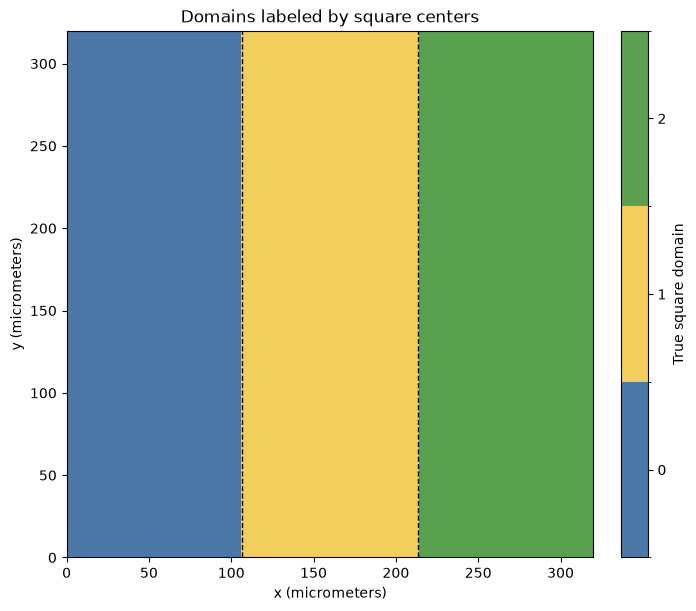

In [12]:
domain_grid = domains_df["domain"].astype(int).to_numpy().reshape(n_rows, n_cols)
boundaries = [field_width_um * i / K for i in range(1, K)]
cmap = ListedColormap(["#4c78a8", "#f2cf5b", "#59a14f"])
norm = BoundaryNorm(np.arange(K + 1) - 0.5, K)
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
image = ax.imshow(
    domain_grid,
    origin="lower",
    interpolation="nearest",
    extent=[0, field_width_um, 0, field_height_um],
    cmap=cmap,
    norm=norm,
)
for boundary in boundaries:
    ax.axvline(boundary, color="black", linestyle="--", linewidth=1)
fig.colorbar(image, ax=ax, ticks=range(K), label="True square domain")
ax.set(
    xlabel="x (micrometers)",
    ylabel="y (micrometers)",
    title="Domains labeled by square centers",
)
plt.show()

## Mock cells and probabilistic type assignment
These independently sampled centers can overlap, and disks may cross the outer field edge.
They test this component only. Finite samples will not exactly match configured probabilities.
The following counts are **cell counts**, not transcript composition ground truth.


In [13]:
n_cells = 300
cells_df = pd.DataFrame(
    {
        "cell_id": [f"cell_{i:04d}" for i in range(n_cells)],
        "x_um": rng.uniform(0, field_width_um, n_cells),
        "y_um": rng.uniform(0, field_height_um, n_cells),
        "radius_um": np.full(n_cells, 5.0),
    }
)
original_cells = cells_df.copy(deep=True)
labeled_cells = assign_cell_types(
    cells_df, K, field_width_um, cell_types, domain_probabilities, rng
)
pd.testing.assert_frame_equal(cells_df, original_cells)
counts = pd.crosstab(labeled_cells["domain"], labeled_cells["cell_type"])
counts = counts.reindex(index=range(K), columns=cell_types, fill_value=0)
print("Cell counts by domain and type:")
print(counts.to_string())
print("\nObserved cell-type fractions:")
print(counts.div(counts.sum(axis=1), axis=0).round(3).to_string())

Cell counts by domain and type:
cell_type   A   B   C
domain               
0          92   8  10
1          12  70  10
2          10  13  75

Observed cell-type fractions:
cell_type      A      B      C
domain                        
0          0.836  0.073  0.091
1          0.130  0.761  0.109
2          0.102  0.133  0.765


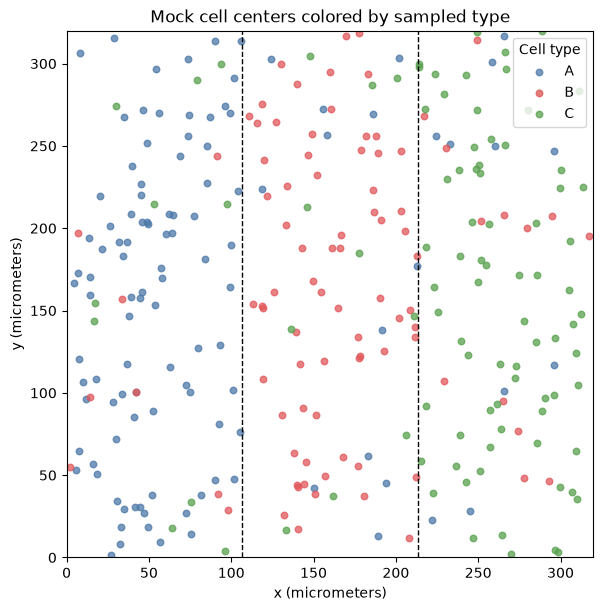

In [14]:
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
for boundary in boundaries:
    ax.axvline(boundary, color="black", linestyle="--", linewidth=1)
for name, color in zip(cell_types, ["#4c78a8", "#e15759", "#59a14f"], strict=True):
    subset = labeled_cells.loc[labeled_cells["cell_type"] == name]
    ax.scatter(
        subset["x_um"], subset["y_um"], s=22, color=color, alpha=0.75, label=name
    )
ax.set(
    xlim=(0, field_width_um),
    ylim=(0, field_height_um),
    aspect="equal",
    xlabel="x (micrometers)",
    ylabel="y (micrometers)",
    title="Mock cell centers colored by sampled type",
)
ax.legend(title="Cell type")
plt.show()

## Boundary example and checks
For width 200 and K=2, a cell centered at x=98 with radius 5 belongs to Domain 0,
although its disk extends to x=103 in Domain 1.
A square centered at x=101 receives Domain 1 independently of that cell.
The exact boundary x=100 belongs to Domain 1.
Transcript generation is outside this module.


In [15]:
boundary_cell = pd.DataFrame(
    {"cell_id": ["crossing"], "x_um": [98.0], "y_um": [10.0], "radius_um": [5.0]}
)
# Use the existing shared generator; deterministic probabilities fix the type.
example = assign_cell_types(boundary_cell, 2, 200, ["A", "B"], np.eye(2), rng)
assert example.loc[0, "domain"] == 0
assert example.loc[0, "cell_type"] == "A"
assert get_domain_id(100, 10, 2, 200) == 1
assert get_domain_id(np.nextafter(100.0, 0), 10, 2, 200) == 0
assert get_domain_id(101, 10, 2, 200) == 1
assert np.all(np.diff(domain_grid, axis=1) >= 0)
assert np.all(domain_grid == domain_grid[0])
assert not domains_df.isna().any().any()
assert labeled_cells["cell_type"].isin(cell_types).all()
assert labeled_cells["domain"].between(0, K - 1).all()
print(example.to_string(index=False))
print("Boundary and component assertions passed.")

 cell_id  x_um  y_um  radius_um  domain cell_type
crossing  98.0  10.0        5.0       0         A
Boundary and component assertions passed.


## Export to the testing folder
The CSV files go into `results/test_simulation/`; rerunning replaces those demo files.
Ensure `results/` is covered by the group repository's `.gitignore`.
`labeled_cells.csv` is for debugging and must not enter dataset ground truth.
CSV has no dtype schema: specify string dtypes when loading domain labels.
The scientific module itself performs no file I/O.


In [16]:
output_dir = project_root / "results/test_simulation"
output_dir.mkdir(parents=True, exist_ok=True)
ground_truth_dir = output_dir / "ground_truth"
ground_truth_dir.mkdir(exist_ok=True)
domains_df.to_csv(ground_truth_dir / "domains.csv", index=False)
labeled_cells.to_csv(output_dir / "labeled_cells.csv", index=False)
reloaded = pd.read_csv(
    ground_truth_dir / "domains.csv", dtype={"square_id": "string", "domain": "string"}
)
assert reloaded.columns.tolist() == ["square_id", "domain"]
assert reloaded["square_id"].tolist() == domains_df["square_id"].tolist()
assert reloaded["domain"].tolist() == domains_df["domain"].tolist()
assert len(reloaded) == 25600
print(f"Component CSV artifacts: {output_dir}")
print("CSV round-trip assertions passed.")

Component CSV artifacts: /Users/ronjasalathe/pls_2026_simulation/results/test_simulation
CSV round-trip assertions passed.
